# Multibranch pretraining

This notebook uses supervised gesture pretraining, then fine-tunes target gestures.

Edit GRID_PARAM_SPACE for grid/Bayesian candidates, EVOLUTIONARY_PARAM_SPACE
for evolutionary candidates, and PRETRAINING_PARAM_SPACE for stage settings.

Validation defaults to complete sequences. Add subject validation in
VALIDATION_PARAM_SPACE to run a separate search with wearers held apart.


# Multi-Branch BERT / Attention — Transfer and Self-Supervised Learning

Model 1 predicts individual pretraining gesture labels, transfers the shared branch/fusion/BERT weights, then fine-tunes the downstream classifier. Model 2 learns masked sensor reconstruction before the same fine-tuning stage. Switch between them in the configuration cell; architecture and preprocessing controls remain shared.

The notebook follows the existing V1 layout: configuration, data loading, split, estimator, grid/Bayesian/evolutionary parameters, holdout evaluation and saving.

In [1]:
import os
import sys
import warnings
import json
import importlib
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import tensorflow as tf

warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

# Local path routing
current_dir = os.getcwd()
workspace_root = current_dir
if os.path.basename(current_dir) == 'notebooks':
    workspace_root = os.path.dirname(current_dir)

src_path = os.path.join(workspace_root, 'src')
sys.path.insert(0, workspace_root)
sys.path.insert(0, src_path)

# Robust Kaggle path routing (handles nested folders from zip uploads)
if os.path.exists('/kaggle/input'):
    for root, dirs, files in os.walk('/kaggle/input'):
        # If we find our custom modules in this directory, add it to sys.path
        if 'base_utils.py' in files or 'multibranch_utils.py' in files:
            if root not in sys.path:
                sys.path.insert(0, root)

# Prefer the exact local source snapshot when this notebook is packaged.
sys.path.insert(0, src_path)

from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit
from sklearn.pipeline import Pipeline

try:
    import skopt
    from skopt import BayesSearchCV
    from skopt.space import Categorical, Integer, Real
    SKOPT_AVAILABLE = True
except ImportError:
    BayesSearchCV = None
    Categorical = Integer = Real = None
    SKOPT_AVAILABLE = False

import base_utils as data_utils
import multibranch_utils as multibranch_keras
import pretraining_utils as pretraining_keras
from pretraining_search import run_validation_searches
importlib.reload(multibranch_keras)
importlib.reload(pretraining_keras)
from base_utils import (
    SequenceExtractor,
    SensorAugmentor,
    ECat,
    EInt,
    EFloat,
    GASearchCV,
    build_quick_results_df,
    evaluate_holdout,
    prepare_bayesian_space,
    prepare_evolutionary_space,
)
from multibranch_utils import (
    candidate_score, refit_valid_candidate,
    HierarchicalGASearchCV, HierarchicalBayesSearchCV,
)
import matplotlib.pyplot as plt
from pathlib import Path

print('Imports loaded successfully')
print('GPU devices:', tf.config.list_physical_devices('GPU'))

# Keep fitting errors visible even when other library warnings are quiet.
warnings.filterwarnings('always', message='Candidate skipped:', category=RuntimeWarning)

Imports loaded successfully
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
experiment_name = 'multibranch_pretraining_model1_large'

# Supported targets: 'bfrb', 'gesture_action', 'orientation', 'gesture', 'gesture_position'
TARGET_COL = 'bfrb'

# Use sample.csv for a quick smoke test; set False for full train.csv
use_sample_data = False
sample_file = 'sample.csv'

search_mode = 'bayes'  # 'best params', 'evo', 'bayes', or 'grid'
quick_save = True         # Always save CV/best/holdout CSVs; False also saves model weights.
random_state = 42
n_splits = 1              # 1 -> GroupShuffleSplit; >=2 -> GroupKFold

train_size = 0.5
n_iter = 20
verbose = 3
epoch_verbosity = 2
error_score = -1.0  # finite penalty; valid F1 scores are >= 0
n_jobs = 1                 # TensorFlow models should not be fitted in parallel

# Evolutionary controls: initial population plus the configured generations.
# Probabilities are per pair (crossover) and per parameter (mutation).
population_size = 15
generations = 3
tournament_size = 3
elitism = True
crossover_probability = 0.7
mutation_probability = 0.15

# Model 1 = supervised transfer; model 2 = masked-signal SSL then fine-tuning.
MODEL_VARIANT = 'model_1'
MODEL_MODES = {'model_1': 'supervised', 'model_2': 'masked_ssl'}

# Optional heads: enable them independently or vary their settings in the search spaces.
USE_ORIENTATION_AUX_HEAD = False
USE_PHASE_AUX_HEAD = False
ORIENTATION_LOSS_WEIGHT = 0.2
PHASE_LOSS_WEIGHT = 0.2
# Callable (partition_dataframe, extracted_chunks) -> integer array (chunks, timesteps).
# Called separately for each CV/internal-validation partition. None skips phase candidates.
PHASE_LABEL_PROVIDER = None
# Any target column constant within a sequence can be used (classification or regression).
# Window heads read the last window_size valid timesteps of the shared chunk representation.
# Window size must not exceed chunk_window_size; sizes are timesteps, not seconds.
NO_CUSTOM_AUX_HEADS = []

generic_aux_heads = [
    {'name': 'short_window', 'target': TARGET_COL, 'window_size': 50,
     'hidden_units': [32], 'dropout': 0.1, 'loss_weight': 0.2},
    {'name': 'long_window', 'target': TARGET_COL, 'window_size': 250,
     'hidden_units': [64], 'dropout': 0.1, 'loss_weight': 0.2},
    {'name': 'action_aux', 'target': 'gesture_action', 'loss_weight': 0.2},
    {'name': 'numeric_aux', 'target': 'your_numeric_column', 'task': 'regression',
     'hidden_units': [32, 16], 'loss_weight': 0.1},
]

competition_custom_aux_heads = [
    {'name': 'action_aux', 'target': 'gesture_action',
     'hidden_units': [64, 32], 'dropout': 0.2, 'loss_weight': 0.3},
    {'name': 'position_aux', 'target': 'gesture_position',
     'hidden_units': [64, 32], 'dropout': 0.2, 'loss_weight': 0.3},
]

multi_scale_custom_aux_heads = [
    {'name': 'short_window', 'target': TARGET_COL, 'window_size': 50,
     'hidden_units': [32], 'dropout': 0.1, 'loss_weight': 0.15},
    {'name': 'long_window', 'target': TARGET_COL, 'window_size': 250,
     'hidden_units': [64], 'dropout': 0.1, 'loss_weight': 0.15},
]

qwen_custom_aux_heads = [
    {'name': 'action_aux', 'target': 'gesture_action',
     'hidden_units': [64, 32], 'dropout': 0.2, 'loss_weight': 0.3},
    {'name': 'position_aux', 'target': 'gesture_position',
     'hidden_units': [64, 32], 'dropout': 0.2, 'loss_weight': 0.3},
    {'name': 'short_window', 'target': TARGET_COL, 'window_size': 50,
     'hidden_units': [32], 'dropout': 0.1, 'loss_weight': 0.15},
    {'name': 'orient_aux', 'target': 'orientation',
     'hidden_units': [32], 'dropout': 0.1, 'loss_weight': 0.2},
]

INVALID_CANDIDATE_POLICY = 'penalize'  # 'raise' for debugging

orientation_filter_list = [] # 'Seated Lean Non Dom - FACE DOWN', 'Lie on Side - Non Dominant', 'Seated Straight', 'Lie on Back'
gesture_position_filter_list = [] # 'Neck', 'Above ear', 'Cheek', 'Eyelash', 'Eyebrow', 'Forehead'
gesture_filter_list = [] # 'Cheek - pinch skin', 'Eyelash - pull hair', 'Eyebrow - pull hair', 'Forehead - scratch', 'Forehead - pull hairline'

problematic_sequence_bool = False

target_only_bool = False  # Keep both domains until the extractor selects each stage.

results_dir = Path(workspace_root) / f'results_{experiment_name}_{TARGET_COL}_{search_mode}'
results_dir.mkdir(parents=True, exist_ok=True)
timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')

search_mode = str(search_mode).strip().lower()
if search_mode not in ('best params', 'evo', 'bayes', 'grid'):
    raise ValueError("search_mode must be 'best params', 'evo', 'bayes', or 'grid'")

if n_splits <= 1:
    cv_object = GroupShuffleSplit(
        n_splits=1,
        test_size=(1 - train_size),
        random_state=random_state,
    )
else:
    cv_object = GroupKFold(n_splits=n_splits)


if MODEL_VARIANT not in MODEL_MODES:
    raise ValueError("MODEL_VARIANT must be 'model_1' or 'model_2'.")
PRETRAINING_MODE = MODEL_MODES[MODEL_VARIANT]

PROBLEMATIC_IDEAL_SKEW_THRESHOLD = 1.6
PROBLEMATIC_FEATURES_THRESHOLD = 7
PROBLEMATIC_FEATURE_COLUMNS = ['acc_x', 'acc_y', 'acc_z', 'rot_x', 'rot_y', 'rot_w', 'rot_z']

BAYES_INITIAL_POINTS_PER_SOURCE = 3

VALIDATION_PARAM_SPACE = {
    'validation_mode': ['sequence'],
    'group_column': ['subject'],
}


In [3]:
# Fixed configuration for best params mode.
BEST_PARAMS = {'estimator__activation': 'relu',
 'estimator__augmentor__augmentations': '[]',
 'estimator__augmentor__noise_std': 0.0,
 'estimator__augmentor__per_aug_prob': 0.0,
 'estimator__augmentor__prob': 0.0,
 'estimator__augmentor__temporal_mask_frac': 0.0,
 'estimator__augmentor__temporal_num_masks': 0,
 'estimator__augmentor__time_shift_frac': 0.0,
 'estimator__batch_size': 128,
 'estimator__branch_dense_units': 225,
 'estimator__branch_filter_mode': 'constant',
 'estimator__branch_filters': '{"acc": 128, "cwt": 16, "rotation": 128, "stft": 16, "thermo": 32, "tof": '
                              '128}',
 'estimator__branch_kernel_sizes': '{"acc": 7, "cwt": 3, "rotation": 7, "stft": 3, "thermo": 3, "tof": 7}',
 'estimator__branch_num_conv_layers': '{"acc": 4, "cwt": 4, "rotation": 4, "stft": 4, "thermo": 2, "tof": 4}',
 'estimator__branch_pool_sizes': '{"acc": 1, "cwt": 1, "rotation": 1, "stft": 1, "thermo": 1, "tof": 1}',
 'estimator__class_weight_mode': 'balanced',
 'estimator__conv_dropout': 0.0,
 'estimator__cosine_t_max': 50,
 'estimator__dense_units': 128,
 'estimator__dropout': 0.0,
 'estimator__early_stopping_patience': 20,
 'estimator__epochs': 150,
 'estimator__extractor__acc_modes': 'smoothed|velocity|displacement|jerk',
 'estimator__extractor__add_global_context': False,
 'estimator__extractor__chunk_stride': 50,
 'estimator__extractor__chunk_stride_ratio': 0.9,
 'estimator__extractor__chunk_window_size': 200,
 'estimator__extractor__clip_value': None,
 'estimator__extractor__compute_dt': False,
 'estimator__extractor__cwt_configs': '[{"max_scale": 16, "n_scales": 8, "name": "cwt_morl", "wavelet": '
                                      '"morl"}]',
 'estimator__extractor__dead_reckoning_detrend': False,
 'estimator__extractor__filter_problematic_sequences': True,
 'estimator__extractor__final_window_mode': 'overlap',
 'estimator__extractor__fix_quaternion_sign': True,
 'estimator__extractor__ideal_skew_threshold': 1.6,
 'estimator__extractor__imu_native_sampling_rate': 100,
 'estimator__extractor__imu_target_sampling_rate': 100,
 'estimator__extractor__interp_mode': 'linear',
 'estimator__extractor__kalman_measurement_noise': 0.01,
 'estimator__extractor__kalman_process_noise': 0.0001,
 'estimator__extractor__linear_acc_mode': 'baseline',
 'estimator__extractor__max_windows_per_sequence': 150,
 'estimator__extractor__maxlen': None,
 'estimator__extractor__motion_filter_mode': None,
 'estimator__extractor__output_format': 'chunks',
 'estimator__extractor__padding_value': 0.0,
 'estimator__extractor__problematic_feature_cols': '["acc_x", "acc_y", "acc_z", "rot_x", "rot_y", "rot_w", '
                                                   '"rot_z"]',
 'estimator__extractor__problematic_features_threshold': 7,
 'estimator__extractor__resample_modalities': False,
 'estimator__extractor__rot_native_sampling_rate': 100,
 'estimator__extractor__rot_target_sampling_rate': 100,
 'estimator__extractor__rotation_modes': 'quaternion|euler|angular_velocity',
 'estimator__extractor__sequence_crop_mode': 'none',
 'estimator__extractor__smooth_alpha': None,
 'estimator__extractor__stft_configs': '[{"name": "stft_default", "noverlap": 16, "nperseg": 32}]',
 'estimator__extractor__thm_modes': 'centered_diff',
 'estimator__extractor__thm_native_sampling_rate': 20,
 'estimator__extractor__thm_target_sampling_rate': 20,
 'estimator__extractor__tof_fill_mode': 'far_500',
 'estimator__extractor__tof_modes': 'pooled_stats|sensor_stats',
 'estimator__extractor__tof_n_sensors': None,
 'estimator__extractor__tof_native_sampling_rate': 20,
 'estimator__extractor__tof_target_sampling_rate': 20,
 'estimator__extractor__use_acc_magnitude': True,
 'estimator__extractor__use_chunk_stride_ratio': True,
 'estimator__extractor__use_dead_reckoning': False,
 'estimator__extractor__use_highpass_fallback': True,
 'estimator__extractor__use_linear_acc_magnitude': True,
 'estimator__extractor__window_cap_policy': 'uniform',
 'estimator__extractor__window_size': 5,
 'estimator__gradient_clip_norm': None,
 'estimator__gradient_clip_value': None,
 'estimator__label_smoothing': 0.0,
 'estimator__learning_rate': 0.0001,
 'estimator__loss_name': 'focal',
 'estimator__lr_scheduler_type': 'cosine',
 'estimator__min_lr': 1e-06,
 'estimator__momentum': 0.0,
 'estimator__optimizer_name': 'adamw',
 'estimator__pooling_mode': 'attention',
 'estimator__static_branch_units': 100,
 'estimator__static_dropout': 0.0,
 'estimator__use_batchnorm': True,
 'estimator__use_lr_scheduler': True,
 'estimator__validation_split': 0.15,
 'estimator__warmup_epochs': 0,
 'estimator__weight_decay': 0.0}


# Prep

In [4]:
# Load and prepare training data without retaining a second sensor frame.
data_root = data_utils.find_data_root()
sample_path = data_root / sample_file
data_path = sample_path if use_sample_data and sample_path.exists() else data_root / 'train.csv'
sensor_columns = [column for column in pd.read_csv(data_path, nrows=0).columns
                  if column.startswith(('acc_', 'rot_', 'tof_', 'thm_'))]
# Store sensor inputs as float32; signal utilities retain their float64 calculations.
train_df = pd.read_csv(data_path, dtype={column: np.float32 for column in sensor_columns})
print(f'Using {data_path.name}: {train_df["sequence_id"].nunique()} sequences')

train_df['gesture'] = train_df['gesture'].fillna('non_bfrb').astype(str)
train_df['orientation'] = train_df['orientation'].fillna('Unknown').astype(str)
train_df['is_target'] = train_df['sequence_type'].eq('Target').astype(np.uint8)
train_df['bfrb'] = train_df['gesture'].where(train_df['is_target'].eq(1), 'non_bfrb')
# Parse each distinct gesture once, rather than once for every sensor timestep.
gesture_parts = {gesture: gesture.split(' - ') for gesture in train_df['gesture'].unique()}
train_df['gesture_position'] = train_df['gesture'].map({gesture: parts[0] for gesture, parts in gesture_parts.items()})
train_df['gesture_action'] = train_df['gesture'].map({gesture: parts[-1] for gesture, parts in gesture_parts.items()})

if TARGET_COL not in {'bfrb', 'gesture_action', 'orientation', 'gesture', 'gesture_position'}:
    raise ValueError('Unsupported TARGET_COL.')

# Apply the configured filters in one row selection.
keep_rows = pd.Series(True, index=train_df.index)
if orientation_filter_list:
    keep_rows &= train_df['orientation'].isin(orientation_filter_list)
if gesture_position_filter_list:
    keep_rows &= train_df['gesture_position'].isin(gesture_position_filter_list)
if gesture_filter_list:
    keep_rows &= train_df['gesture'].isin(gesture_filter_list)
if target_only_bool:
    raise ValueError('Keep target_only_bool=False; select target/non-target within the stage extractor.')
if not keep_rows.all():
    train_df = train_df.loc[keep_rows].copy()
del keep_rows, gesture_parts

# Orientation-based features require at least one valid quaternion per sequence.
# Entirely missing orientation cannot be repaired by within-sequence interpolation.
quaternion_cols = ['rot_w', 'rot_x', 'rot_y', 'rot_z']
quaternions = train_df[quaternion_cols].to_numpy(dtype=np.float64)
valid_quaternion = np.isfinite(quaternions).all(axis=1) & (np.linalg.norm(quaternions, axis=1) > 0)
orientation_available = pd.Series(valid_quaternion, index=train_df.index).groupby(train_df['sequence_id']).any()
excluded_orientation_ids = orientation_available.index[~orientation_available].tolist()
if excluded_orientation_ids:
    print(f'Excluding {len(excluded_orientation_ids)} sequences with no valid orientation before splitting.')
    train_df = train_df[~train_df['sequence_id'].isin(excluded_orientation_ids)].copy()
with open(results_dir / f'{timestamp}_input_exclusions.json', 'w') as stream:
    json.dump({'reason': 'no finite nonzero quaternion in sequence',
               'sequence_ids': excluded_orientation_ids,
               'evaluation_scope': 'sequences with orientation data'}, stream, indent=2)

del quaternions, valid_quaternion, orientation_available

train_df[TARGET_COL] = train_df[TARGET_COL].fillna('non_bfrb').astype(str)
print(f'Target: {TARGET_COL}; sequences after filters: {train_df["sequence_id"].nunique()}')

Using Kaggle data folder: /kaggle/input/competitions/cmi-detect-behavior-with-sensor-data
Using train.csv: 8151 sequences
Excluding 50 sequences with no valid orientation before splitting.
Target: bfrb; sequences after filters: 8101


In [5]:
# Keep complete sequences available; each selected validation protocol splits them
# before stage selection and extraction. Sequence splitting remains the default.
experiment_df = train_df
del train_df
print('Available sequences:', experiment_df['sequence_id'].nunique())


Available sequences: 8101


In [6]:
# Explicit [{}] is equivalent to the extractor's default STFT/CWT configuration.
# It also keeps those defaults serialisable in grid/Bayesian/evolutionary spaces.
extractor = SequenceExtractor(
    output_format='chunks',
    stft_configs=[{}],
    cwt_configs=[{}],
    filter_problematic_sequences=problematic_sequence_bool,
    ideal_skew_threshold=PROBLEMATIC_IDEAL_SKEW_THRESHOLD,
    problematic_features_threshold=PROBLEMATIC_FEATURES_THRESHOLD,
    problematic_feature_cols=PROBLEMATIC_FEATURE_COLUMNS,
)

clf = pretraining_keras.AdvancedMultiBranchSequenceClassifier(
    extractor=extractor,
    augmentor=SensorAugmentor(
        sequence_col='sequence_id', counter_col='sequence_counter',
        prob=0.0, per_aug_prob=0.0,
    ),
    primary_target=TARGET_COL,
    pretraining_validation_group_column=None,
    validation_group_column=None,
    temporal_architecture='bert',
    use_bigru=False,
    use_orientation_aux_head=USE_ORIENTATION_AUX_HEAD,
    use_phase_aux_head=USE_PHASE_AUX_HEAD,
    custom_aux_heads=NO_CUSTOM_AUX_HEADS,
    orientation_loss_weight=ORIENTATION_LOSS_WEIGHT,
    phase_loss_weight=PHASE_LOSS_WEIGHT,
    phase_label_provider=PHASE_LABEL_PROVIDER,
    invalid_candidate_policy=INVALID_CANDIDATE_POLICY,
    candidate_failure_log=str(results_dir / f'{timestamp}_candidate_failures.jsonl'),
    verbose=epoch_verbosity,
    random_state=random_state,
)
pipeline = Pipeline([('estimator', clf)])

# Params

In [ ]:
# ============================================================
# Branch filter / depth candidates (unchanged)
# ============================================================

SEARCH_BRANCH_FILTERS = [
    {'acc': 64, 'rotation': 64, 'tof': 64, 'thermo': 32, 'stft': 64, 'cwt': 64},
    {'acc': 128, 'rotation': 128, 'tof': 128, 'thermo': 32, 'stft': 128, 'cwt': 128},
    {'acc': 160, 'rotation': 160, 'tof': 160, 'thermo': 32, 'stft': 160, 'cwt': 160},
]

SEARCH_BRANCH_DEPTHS = [
    # {'acc': 2, 'rotation': 2, 'tof': 2, 'thermo': 1, 'stft': 1, 'cwt': 1},
    # {'acc': 2, 'rotation': 2, 'tof': 2, 'thermo': 1, 'stft': 2, 'cwt': 2},
    # {'acc': 3, 'rotation': 3, 'tof': 2, 'thermo': 1, 'stft': 1, 'cwt': 2},
    {'acc': 4, 'rotation': 4, 'tof': 4, 'thermo': 2, 'stft': 1, 'cwt': 1},
    {'acc': 4, 'rotation': 4, 'tof': 4, 'thermo': 2, 'stft': 4, 'cwt': 4},
]

SEARCH_CUSTOM_FILTERS = [
    {
        'acc': [32, 64, 64],
        'rotation': [32, 64, 64],
        'tof': [32, 64],
        'thermo': [32],
        'stft': [32],
        'cwt': [32],
    },
]

SEARCH_CONSTANT_FILTERS = [
    # {'acc': 16, 'rotation': 16, 'tof': 16, 'thermo': 16, 'stft': 16, 'cwt': 16},
    # {'acc': 32, 'rotation': 32, 'tof': 32, 'thermo': 32, 'stft': 16, 'cwt': 16},
    # {'acc': 64, 'rotation': 64, 'tof': 64, 'thermo': 32, 'stft': 32, 'cwt': 32},
    {'acc': 128, 'rotation': 128, 'tof': 128, 'thermo': 32, 'stft': 16, 'cwt': 16},
    # {'acc': 128, 'rotation': 128, 'tof': 128, 'thermo': 32, 'stft': 32, 'cwt': 32},
    # {'acc': 167, 'rotation': 167, 'tof': 167, 'thermo': 16, 'stft': 64, 'cwt': 64},
    #{'acc': 200, 'rotation': 200, 'tof': 200, 'thermo': 32, 'stft': 64, 'cwt': 64},
]

branch_filter_mode = 'constant'  # 'custom', 'double', or 'constant'

if branch_filter_mode == 'custom':
    branch_filter_candidates = SEARCH_CUSTOM_FILTERS
    branch_depth_candidates = [{
        'acc': 3, 'rotation': 3, 'tof': 2,
        'thermo': 1, 'stft': 1, 'cwt': 1,
    }]
else:
    if branch_filter_mode == 'double':
        branch_filter_candidates = SEARCH_BRANCH_FILTERS
    elif branch_filter_mode == 'constant':
        branch_filter_candidates = SEARCH_CONSTANT_FILTERS
    else:
        raise ValueError("branch_filter_mode must be 'custom', 'double', or 'constant'.")
    branch_depth_candidates = SEARCH_BRANCH_DEPTHS


# ============================================================
# Acquisition-rate assumptions (configurable; not verified hardware metadata).
IMU_ASSUMED_FS_HZ = 100.0
ROT_ASSUMED_FS_HZ = 100.0
TOF_ASSUMED_FS_HZ = 20.0
THERMO_ASSUMED_FS_HZ = 20.0

# STFT / CWT config-list candidates
# ============================================================

STFT_CONFIGS = [
     None,
    # [{'name': 'stft_default', 'nperseg': 8, 'noverlap': 4}],
    # [{'name': 'stft_default', 'nperseg': 16, 'noverlap': 8}],
    # [{'name': 'stft_default', 'window_seconds': 1.0, 'noverlap': 50}],
    # [{'name': 'stft_default', 'nperseg': 64, 'noverlap': 32}],
    # [
    #     {'name': 'stft_fast', 'nperseg': 32,  'noverlap': 16},
    #     {'name': 'stft_mid',  'nperseg': 64,  'noverlap': 32},
    #     {'name': 'stft_slow', 'nperseg': 128, 'noverlap': 64},
    # ],
]

CWT_CONFIGS = [
    #  None,
    # [{'name': 'cwt_morl', 'wavelet': 'morl', 'max_scale': 8, 'n_scales': 4}],
    [{'name': 'cwt_morl', 'wavelet': 'morl', 'max_scale': 16, 'n_scales': 8}],
    # [{'name': 'cwt_morl', 'wavelet': 'morl', 'max_scale': 64, 'n_scales': 32}],
    # [
    #     {'name': 'cwt_morl',  'wavelet': 'morl',  'max_scale': 64, 'n_scales': 32},
    #     {'name': 'cwt_mexh',  'wavelet': 'mexh',  'max_scale': 64, 'n_scales': 32},
    #     {'name': 'cwt_gaus2', 'wavelet': 'gaus2', 'max_scale': 64, 'n_scales': 32},
    # ],
]


# ============================================================
# FULL GRID / BAYESIAN PARAM SPACE
# ============================================================

GRID_PARAM_SPACE = {
    # ----------------------------------------------------------
    # AUGMENTOR (disabled; applied only inside estimator.fit)
    # ----------------------------------------------------------
    'estimator__augmentor__prob':                [0.0],
    'estimator__augmentor__per_aug_prob':        [0.0],
    'estimator__augmentor__augmentations':       [None],
    'estimator__augmentor__sensor_drop_prob':    [0.0],
    'estimator__augmentor__noise_std':           [0.0],
    'estimator__augmentor__jitter_sigma':        [0.0],
    'estimator__augmentor__scaling_sigma':       [0.0],
    'estimator__augmentor__channel_drop_prob':   [0.0],
    'estimator__augmentor__time_shift_frac':     [0.0],
    'estimator__augmentor__temporal_num_masks':  [0],
    'estimator__augmentor__temporal_mask_frac':  [0.0],
    'estimator__augmentor__warp_sigma':          [0.0],
    'estimator__augmentor__warp_num_knots':      [0],
    'estimator__augmentor__crop_frac_range':     [(1.0, 1.0)],

    # ----------------------------------------------------------
    # EXTRACTOR â€” accelerometer
    # ----------------------------------------------------------
    'estimator__extractor__acc_modes': [
        'smoothed|velocity|displacement|jerk',
        'raw|smoothed|velocity|displacement|jerk',
        'smoothed|jerk',
        'raw|jerk',
        'raw|smoothed|jerk',
        'smoothed|velocity|jerk',
        'raw',
        'jerk',
        'velocity',
        'displacement'
        # None,
    ],
    'estimator__extractor__use_acc_magnitude':         [True],
    'estimator__extractor__use_linear_acc_magnitude':  [True],
    'estimator__extractor__linear_acc_mode':           [
        # None, 
                                                         'baseline'
                                                       ],
    'estimator__extractor__use_highpass_fallback':     [True],

    # ----------------------------------------------------------
    # EXTRACTOR â€” rotation
    # ----------------------------------------------------------
    'estimator__extractor__rotation_modes': [
        # None,
        'quaternion|euler|angular_velocity',
        # 'euler|angular_velocity',
        # 'quaternion',
        # 'rot6d',
        # 'raw'
    ],
    'estimator__extractor__fix_quaternion_sign': [True],

    # ----------------------------------------------------------
    # EXTRACTOR â€” ToF
    # ----------------------------------------------------------
    'estimator__extractor__tof_modes':      [
        'pooled_stats|sensor_stats',
        #   'sensor_stats', 
        #   'raw',
        #     'pooled_stats'
        # None
            ],
    'estimator__extractor__tof_fill_mode':  [
                                            # 'far_255',
                                              'far_500'
                                              ],
    'estimator__extractor__tof_n_sensors':  [None],

    # ----------------------------------------------------------
    # EXTRACTOR â€” thermo
    # ----------------------------------------------------------
    'estimator__extractor__thm_modes': [
        'centered_diff', 
                                        # 'centered', 
                                        # 'diff', 'raw', 'centered|diff'
                                        # None,
                                        ],

    # ----------------------------------------------------------
    # EXTRACTOR â€” signal cleaning / motion
    # ----------------------------------------------------------
    'estimator__extractor__motion_filter_mode':     [None],
    'estimator__extractor__use_dead_reckoning':     [False],
    'estimator__extractor__dead_reckoning_detrend': [False],
    'estimator__extractor__kalman_process_noise':       [1e-4],
    'estimator__extractor__kalman_measurement_noise':   [1e-2],
    'estimator__extractor__window_size':   [5],
    'estimator__extractor__smooth_alpha':  [None],
    'estimator__extractor__clip_value':    [None],
    'estimator__extractor__interp_mode':   ['linear'],

    # ----------------------------------------------------------
    # EXTRACTOR â€” chunking
    # ----------------------------------------------------------
    'estimator__extractor__output_format':      ['chunks'],
    'estimator__extractor__padding_value':      [0.0],
    'estimator__extractor__maxlen':             [None],
    'estimator__extractor__sequence_crop_mode': [
        # 'head',
        #   'tail',
        #     'center',
          'none'
          ],
    'estimator__extractor__chunk_window_size':  [250],
    'estimator__extractor__chunk_stride':       [50],
    'estimator__extractor__use_chunk_stride_ratio': [True],
    'estimator__extractor__chunk_stride_ratio':  [0.75],
    'estimator__extractor__final_window_mode':  [
        # 'pad', 
        'overlap'
        ],
    'estimator__extractor__window_cap_policy':  [
        # 'last',
        #   'first',
            'uniform'],
    'estimator__extractor__max_windows_per_sequence': [50, 200],
    'estimator__extractor__add_global_context': [False],
    'estimator__extractor__resample_modalities':[False],
    'estimator__extractor__compute_dt':         [False],

    # ----------------------------------------------------------
    # EXTRACTOR â€” sampling rates
    # ----------------------------------------------------------
    'estimator__extractor__imu_native_sampling_rate': [IMU_ASSUMED_FS_HZ],
    'estimator__extractor__rot_native_sampling_rate': [ROT_ASSUMED_FS_HZ],
    'estimator__extractor__tof_native_sampling_rate': [TOF_ASSUMED_FS_HZ],
    'estimator__extractor__thm_native_sampling_rate': [THERMO_ASSUMED_FS_HZ],
    'estimator__extractor__imu_target_sampling_rate': [IMU_ASSUMED_FS_HZ],
    'estimator__extractor__rot_target_sampling_rate': [ROT_ASSUMED_FS_HZ],
    'estimator__extractor__tof_target_sampling_rate': [TOF_ASSUMED_FS_HZ],
    'estimator__extractor__thm_target_sampling_rate': [THERMO_ASSUMED_FS_HZ],

    # ----------------------------------------------------------
    # EXTRACTOR â€” STFT/CWT
    # ----------------------------------------------------------
    'estimator__extractor__stft_configs':       STFT_CONFIGS,
    'estimator__extractor__cwt_configs':       CWT_CONFIGS,

    # ----------------------------------------------------------
    # EXTRACTOR â€” problematic-sequence filter
    # ----------------------------------------------------------
    'estimator__extractor__filter_problematic_sequences':   [problematic_sequence_bool],
    'estimator__extractor__ideal_skew_threshold':           [1.7],
    'estimator__extractor__problematic_features_threshold': [7],
    'estimator__extractor__problematic_feature_cols': [
        # None,
        ['acc_x', 'acc_y', 'acc_z', 'rot_x', 'rot_y', 'rot_w', 'rot_z'],
    ],

    # ----------------------------------------------------------
    # MODEL â€” branch architecture
    # ----------------------------------------------------------
    'estimator__branch_filters':          branch_filter_candidates,
    'estimator__branch_num_conv_layers':  branch_depth_candidates,
    'estimator__branch_filter_mode':      [branch_filter_mode],
    'estimator__branch_kernel_sizes': [
        # {'acc': 3,  'rotation': 3,  'tof': 3, 'thermo': 3, 'stft': 3, 'cwt': 3},
        # {'acc': 5,  'rotation': 5,  'tof': 3, 'thermo': 3, 'stft': 3, 'cwt': 3},
        # {'acc': 7,  'rotation': 7,  'tof': 5, 'thermo': 3, 'stft': 3, 'cwt': 3},
        {'acc': 7,  'rotation': 7,  'tof': 7, 'thermo': 3, 'stft': 3, 'cwt': 3},
        # {'acc': 8, 'rotation': 8, 'tof': 8, 'thermo': 3, 'stft': 3, 'cwt': 3},
    ],
    'estimator__branch_pool_sizes': [
        {'acc': 1, 'rotation': 1, 'tof': 1, 'thermo': 1, 'stft': 1, 'cwt': 1},
        # {'acc': 2, 'rotation': 2, 'tof': 2, 'thermo': 1, 'stft': 1, 'cwt': 1},
        # {'acc': 3, 'rotation': 3, 'tof': 3, 'thermo': 2, 'stft': 2, 'cwt': 2},
        # {'acc': 4, 'rotation': 4, 'tof': 4, 'thermo': 2, 'stft': 2, 'cwt': 2},
        # {'acc': 5, 'rotation': 5, 'tof': 5, 'thermo': 2, 'stft': 2, 'cwt': 2},
    ],
    'estimator__branch_dense_units':  [225],
    'estimator__static_branch_units':  [100],

    # ----------------------------------------------------------
    # MODEL â€” temporal/fusion architecture
    # ----------------------------------------------------------
    # Commented alternatives: replace existing keys; do not add duplicate keys.
    # Bayesian search inherits these options from GRID_PARAM_SPACE.
    'estimator__temporal_architecture': [
        # 'bert',
        'bigru_attention'
    ], #  'bigru_attention', 'phase_attention', 'cnn_attention_pool', 'bert'
    'estimator__use_bigru': [False],
    'estimator__gru_units': [32],
    'estimator__gru_layers': [1],
    'estimator__gru_dropout': [0.0],
    'estimator__gru_recurrent_dropout': [0.0],
    'estimator__bidirectional_gru': [True],
    'estimator__attention_type': ['additive', 'linear'],
    'estimator__attention_units': [64],
    'estimator__cnn_depth': [4],
    'estimator__cnn_filters': [32],
    'estimator__cnn_kernel_size': [5],
    'estimator__cnn_dropout': [0.0],
    'estimator__use_residual': [False],
    'estimator__use_se': [False],
    'estimator__se_ratio': [4],
    'estimator__n_phases': [3],
    'estimator__phase_attention_units': [16],
    'estimator__phase_attention_temperature': [0.75],
    'estimator__phase_fusion_mode': ['concat'], # concat, sum, learned
    # cnn is an alias for conv1d.
    'estimator__branch_encoder_type': ['conv1d'],
    'estimator__branch_cnn_filters': [32],
    'estimator__branch_cnn_kernel_size': [6],
    'estimator__branch_cnn_depth': [3],
    'estimator__branch_dropout': [0.0],
    'estimator__post_fusion_attention_type': ['additive'], # additive, linear
    'estimator__post_fusion_attention_units': [64],
    'estimator__post_fusion_pooling': ['attention'], # 'attention', 'avg', 'max', 'avg_max', 'attention_avg_max'
    'estimator__bert_num_layers': [4],
    'estimator__bert_d_model': [300],
    'estimator__bert_num_heads': [5],
    'estimator__bert_ff_dim': [256],
    'estimator__bert_dropout': [0.0],
    'estimator__bert_attention_dropout': [0.0],
    'estimator__bert_activation': ['relu'], # gelu, relu
    'estimator__bert_pooling': ['attention'], # attention, avg , avg_max
    # CLS pooling requires bert_use_cls_token=True; replace both entries together.
    'estimator__bert_use_cls_token': [False],
    # Enable the BERT CLS token.

    'estimator__bert_positional_encoding': ['sinusoidal'], # learned, sinusoidal
    # 'estimator__tof_encoder_type': ['flatten_1d'],
    # Spatial ToF requires extractor__tof_modes='raw' (8x8 pixel groups).
    'estimator__tof_encoder_type': ['flatten_1d'],
    'estimator__tof_spatial_filters': [8],
    'estimator__tof_spatial_kernel_size': [3],
    'estimator__tof_spatial_depth': [1],
    'estimator__tof_gru_units': [16],
    'estimator__fusion_type': ['attention'],
    'estimator__fusion_units': [128],
    'estimator__fusion_dropout': [0.0],
    'estimator__use_orientation_aux_head': [USE_ORIENTATION_AUX_HEAD],
    # 'estimator__orientation_num_classes': [4],  # Inferred from orientation labels during fit.
    # Requires y with an 'orientation' column instead of the current 1-D target.
    # 'estimator__use_orientation_aux_head': [True],
    'estimator__use_phase_aux_head': [USE_PHASE_AUX_HEAD],
    'estimator__custom_aux_heads': [NO_CUSTOM_AUX_HEADS],
    'estimator__orientation_loss_weight': [ORIENTATION_LOSS_WEIGHT],
    'estimator__phase_loss_weight': [PHASE_LOSS_WEIGHT],
    # Optional replacements to search head combinations and strengths:
    # 'estimator__custom_aux_heads': [[], CUSTOM_AUX_HEADS],
    # 'estimator__orientation_loss_weight': [0.1, 0.2, 0.5],
    # 'estimator__phase_loss_weight': [0.1, 0.2, 0.5],
    # Requires PHASE_LABEL_PROVIDER; otherwise this candidate receives the penalty.
    # 'estimator__use_phase_aux_head': [True],

    # ----------------------------------------------------------
    # MODEL â€” head, regularization, activation, pooling
    # ----------------------------------------------------------
    'estimator__conv_dropout':    [0.0],
    'estimator__static_dropout':  [0.0],
    'estimator__dense_units':     [128],
    'estimator__dropout':         [0.0],
    'estimator__use_batchnorm':   [True],
    'estimator__activation':      [
        'relu', 
                                #    'gelu', 
                                #    'swish',
                                    # 'elu',
                                    #   'leaky'
                                      ],
    'estimator__pooling_mode':    [
        'attention'
                                #    , 'mean'
                                   ],

    # ----------------------------------------------------------
    # MODEL â€” optimizer
    # ----------------------------------------------------------
    'estimator__optimizer_name':      [
                                        # 'adam', 
                                        'adamw', 
                                        # 'rmsprop', 
                                    #    'sgd', 
                                    #    'nadam',
                                        #  'adagrad', 'adadelta'
                                         ],
    'estimator__learning_rate':       [
        1e-6,
        # 5e-5,
        1e-4,
        #   1e-3
        ],
    'estimator__weight_decay':        [0.0], # adam
    'estimator__momentum':            [0.0], # sgd
    'estimator__gradient_clip_norm':  [None],
    'estimator__gradient_clip_value': [None],

    # ----------------------------------------------------------
    # MODEL â€” loss
    # ----------------------------------------------------------
    'estimator__loss_name':       ['focal'], # sparse_cce, focal
    'estimator__label_smoothing': [0.0],

    # ----------------------------------------------------------
    # TRAINING LOOP
    # ----------------------------------------------------------
    'estimator__epochs':                  [150],
    'estimator__batch_size':              [128],
    'estimator__validation_split':        [0.15],
    'estimator__early_stopping_patience': [30],
    'estimator__class_weight_mode':       ['balanced'],

    # ----------------------------------------------------------
    # LR SCHEDULER
    # ----------------------------------------------------------
    'estimator__use_lr_scheduler':   [True],
    'estimator__lr_scheduler_type':  ['plateau'], # plateau, cosine
    'estimator__lr_factor':          [0.5],
    'estimator__lr_patience':        [20],
    'estimator__min_lr':             [1e-6],
    'estimator__cosine_t_max':       [50],
    'estimator__warmup_epochs':      [0],
}


# ============================================================
# SEPARATE EVOLUTIONARY PARAM SPACE
# Includes Grid/Bayesian candidates while retaining existing evolutionary choices.
# Numeric ranges remain ranges and expand only when needed for coverage.
# ============================================================

EVOLUTIONARY_PARAM_SPACE = {

    # ----------------------------------------------------------
    # AUGMENTOR (disabled; applied only inside estimator.fit)
    # ----------------------------------------------------------
    'estimator__augmentor__prob':                ECat([0.0]),
    'estimator__augmentor__per_aug_prob':        ECat([0.0]),
    'estimator__augmentor__augmentations':       ECat([None]),
    'estimator__augmentor__sensor_drop_prob':    ECat([0.0]),
    'estimator__augmentor__noise_std':           ECat([0.0]),
    'estimator__augmentor__jitter_sigma':        ECat([0.0]),
    'estimator__augmentor__scaling_sigma':       ECat([0.0]),
    'estimator__augmentor__channel_drop_prob':   ECat([0.0]),
    'estimator__augmentor__time_shift_frac':     ECat([0.0]),
    'estimator__augmentor__temporal_num_masks':  ECat([0]),
    'estimator__augmentor__temporal_mask_frac':  ECat([0.0]),
    'estimator__augmentor__warp_sigma':          ECat([0.0]),
    'estimator__augmentor__warp_num_knots':      ECat([0]),
    'estimator__augmentor__crop_frac_range':     ECat([(1.0, 1.0)]),

    # ----------------------------------------------------------
    # EXTRACTOR — accelerometer
    # ----------------------------------------------------------
    'estimator__extractor__acc_modes': ECat([
        'smoothed|velocity|displacement|jerk',
    ]),
    'estimator__extractor__use_acc_magnitude':         ECat([ True]),
    'estimator__extractor__use_linear_acc_magnitude':  ECat([True]),
    'estimator__extractor__linear_acc_mode':           ECat(['baseline']),
    'estimator__extractor__linear_acc_modes': ECat([
        # '', 'raw', 'velocity', 'displacement', 'jerk',
        'raw|velocity|displacement|jerk',
    ]),
    'estimator__extractor__linear_acc_frame': ECat(['world', 'body']),
    'estimator__extractor__use_highpass_fallback':     ECat([False, True]),

    # ----------------------------------------------------------
    # EXTRACTOR — rotation
    # ----------------------------------------------------------
    'estimator__extractor__rotation_modes': ECat([
        'quaternion|euler|angular_velocity',
    ]),
    'estimator__extractor__fix_quaternion_sign': ECat([True]),

    # ----------------------------------------------------------
    # EXTRACTOR — ToF
    # ----------------------------------------------------------
    'estimator__extractor__tof_modes':      ECat(['pooled_stats|sensor_stats', 'raw']),
    'estimator__extractor__tof_fill_mode':  ECat(['far_500']),
    'estimator__extractor__tof_n_sensors':  ECat([None]),

    # ----------------------------------------------------------
    # EXTRACTOR — thermo
    # ----------------------------------------------------------
    'estimator__extractor__thm_modes': ECat(['centered_diff']),

    # ----------------------------------------------------------
    # EXTRACTOR — signal cleaning / motion
    # ----------------------------------------------------------
    'estimator__extractor__motion_filter_mode':         ECat([None]),
    'estimator__extractor__use_dead_reckoning':         ECat([False]),
    'estimator__extractor__dead_reckoning_detrend':     ECat([False]),
    'estimator__extractor__kalman_process_noise':       ECat([1e-4]),
    'estimator__extractor__kalman_measurement_noise':   ECat([1e-2]),
    'estimator__extractor__window_size':                ECat([5]),
    'estimator__extractor__smooth_alpha':               ECat([None]),
    'estimator__extractor__clip_value':                 ECat([None]),
    'estimator__extractor__interp_mode':                ECat(['linear']),

    # ----------------------------------------------------------
    # EXTRACTOR — chunking
    # ----------------------------------------------------------
    'estimator__extractor__output_format':            ECat(['chunks']),
    'estimator__extractor__padding_value':            ECat([0.0]),
    'estimator__extractor__maxlen':                   ECat([None]),
    'estimator__extractor__sequence_crop_mode':       ECat(['none']),
    'estimator__extractor__chunk_window_size':        ECat([100, 150, 200, 250, 300, 350, 400]),
    'estimator__extractor__chunk_stride':             ECat([50, 70, 100, 150]),
    'estimator__extractor__use_chunk_stride_ratio':   ECat([True]),
    'estimator__extractor__chunk_stride_ratio':       EFloat(0.2, 0.9),
    'estimator__extractor__final_window_mode':        ECat(['overlap']),
    'estimator__extractor__window_cap_policy':        ECat(['uniform']),
    'estimator__extractor__max_windows_per_sequence': ECat([150, 200]),
    'estimator__extractor__add_global_context':       ECat([False]),
    'estimator__extractor__frame_stats': ECat([
        'mean,std,min,max,last',
        'mean,std,min,max,first,last,median,rms,abs_mean',
        'mean,std,median,rms',
    ]),
    'estimator__extractor__resample_modalities':      ECat([False]),
    'estimator__extractor__compute_dt':               ECat([False]),

    # ----------------------------------------------------------
    # EXTRACTOR — sampling rates
    # ----------------------------------------------------------
    'estimator__extractor__imu_native_sampling_rate': ECat([IMU_ASSUMED_FS_HZ]),
    'estimator__extractor__rot_native_sampling_rate': ECat([ROT_ASSUMED_FS_HZ]),
    'estimator__extractor__tof_native_sampling_rate': ECat([TOF_ASSUMED_FS_HZ]),
    'estimator__extractor__thm_native_sampling_rate': ECat([THERMO_ASSUMED_FS_HZ]),
    'estimator__extractor__imu_target_sampling_rate': ECat([IMU_ASSUMED_FS_HZ]),
    'estimator__extractor__rot_target_sampling_rate': ECat([ROT_ASSUMED_FS_HZ]),
    'estimator__extractor__tof_target_sampling_rate': ECat([TOF_ASSUMED_FS_HZ]),
    'estimator__extractor__thm_target_sampling_rate': ECat([THERMO_ASSUMED_FS_HZ]),

    # ----------------------------------------------------------
    # EXTRACTOR — STFT/CWT
    # ----------------------------------------------------------
    # [{}] inherits the scalar settings below; named configs can override them.
    # Preserve every existing config-list candidate.
    'estimator__extractor__stft_configs': ECat(STFT_CONFIGS),
    'estimator__extractor__cwt_configs':  ECat(CWT_CONFIGS),
    # 'estimator__extractor__stft_nperseg': ECat([8, 16, 32, 64, 128]),
    # 'estimator__extractor__stft_noverlap': ECat([None, 0, 4]),
    # 'estimator__extractor__stft_window_seconds': ECat([None, 0.5, 1.0, 2.0]),
    # 'estimator__extractor__stft_window_type': ECat(['hann', 'hamming', 'blackman', 'boxcar']),
    # 'estimator__extractor__stft_scaling': ECat(['density', 'spectrum', 'magnitude']),
    # 'estimator__extractor__stft_detrend': ECat(['constant', 'linear', False]),
    # 'estimator__extractor__stft_use_log_scale': ECat([True, False]),
    # 'estimator__extractor__stft_frequency_bands': ECat([
    #     None,
    #     {'low': (0.0, 3.0), 'mid': (3.0, 6.0), 'high': (6.0, 10.0)},
    # ]),
    # 'estimator__extractor__cwt_wavelet': ECat(['morl', 'mexh', 'gaus1', 'cmor1.5-1.0']),
    # 'estimator__extractor__cwt_max_scale': EInt(16, 128),
    # 'estimator__extractor__cwt_n_scales': EInt(8, 32),
    # 'estimator__extractor__cwt_use_log_scale': ECat([True, False]),
    # 'estimator__extractor__cwt_min_scale': ECat([None, 4.0, 8.0]),
    # 'estimator__extractor__cwt_max_frequency': ECat([None, 10.0, 20.0]),

    # ----------------------------------------------------------
    # EXTRACTOR — problematic-sequence filter
    # ----------------------------------------------------------
    'estimator__extractor__filter_problematic_sequences':   ECat([problematic_sequence_bool]),
    'estimator__extractor__ideal_skew_threshold':           ECat([1.7]),
    'estimator__extractor__problematic_features_threshold': ECat([7]),
    'estimator__extractor__problematic_feature_cols': ECat([
        ['acc_x', 'acc_y', 'acc_z', 'rot_x', 'rot_y', 'rot_w', 'rot_z'],
    ]),

    # ----------------------------------------------------------
    # MODEL — branch architecture
    # ----------------------------------------------------------
    'estimator__branch_filters':          ECat(branch_filter_candidates),
    'estimator__branch_num_conv_layers':  ECat(branch_depth_candidates),
    'estimator__branch_filter_mode':      ECat([branch_filter_mode]),
    'estimator__branch_kernel_sizes': ECat([
        {'acc': 7, 'rotation': 7, 'tof': 7, 'thermo': 3, 'stft': 3, 'cwt': 3},
        {'acc': 8, 'rotation': 8, 'tof': 8, 'thermo': 3, 'stft': 3, 'cwt': 3},
    ]),
    'estimator__branch_pool_sizes': ECat([
        {'acc': 1, 'rotation': 1, 'tof': 1, 'thermo': 1, 'stft': 1, 'cwt': 1},
    ]),
    'estimator__branch_dense_units':  ECat([225]),
    'estimator__static_branch_units': ECat([100]),

    # ----------------------------------------------------------
    # MODEL — temporal/fusion architecture
    # ----------------------------------------------------------
    # Commented alternatives: replace existing keys; do not add duplicate keys.
    'estimator__temporal_architecture': ECat([
'bert',
    ]),
    'estimator__use_bigru': ECat([False]),
    # 'estimator__gru_units': ECat([32, 64]),
    # 'estimator__gru_layers': EInt(1, 2),
    # 'estimator__gru_dropout': EFloat(0.0, 0.1),
    # 'estimator__gru_recurrent_dropout': ECat([0.0]),
    # 'estimator__bidirectional_gru': ECat([True, False]),
    'estimator__attention_type': ECat(['additive', 'linear']),
    'estimator__attention_units': ECat([32, 64, 100]),
    'estimator__cnn_depth': ECat([1, 2, 3, 4, 5]),
    'estimator__cnn_filters': ECat([32, 64, 96]),
    'estimator__cnn_kernel_size': ECat([3, 5, 7]),
    'estimator__cnn_dropout': ECat([0.0, 0.1]),
    'estimator__use_residual': ECat([False, True]),
    'estimator__use_se': ECat([False, True]),
    'estimator__se_ratio': ECat([4, 8, 16]),
    'estimator__n_phases': ECat([3, 4]),
    'estimator__phase_attention_units': ECat([16, 32, 64]),
    'estimator__phase_attention_temperature': ECat([0.75, 1.0, 1.5]),
    'estimator__phase_fusion_mode': ECat(['concat', 'sum', 'learned']),
    # cnn is an alias for conv1d.
    'estimator__branch_encoder_type': ECat(['conv1d', 'cnn']),
    'estimator__branch_cnn_filters': ECat([16, 32, 64, 128]),
    'estimator__branch_cnn_kernel_size': ECat([3, 5, 6, 7]),
    'estimator__branch_cnn_depth': EInt(1, 4),
    'estimator__branch_dropout': EFloat(0.0, 0.4),
    'estimator__post_fusion_attention_type': ECat(['additive', 'linear']),
    'estimator__post_fusion_attention_units': ECat([32, 64]),
    'estimator__post_fusion_pooling': ECat(['attention', 'avg', 'max', 'avg_max', 'attention_avg_max']),
    'estimator__bert_num_layers': EInt(1, 5),
    'estimator__bert_d_model': ECat([32, 64, 128, 200, 256]),
    'estimator__bert_num_heads': ECat([2, 4, 5, 6]),
    'estimator__bert_ff_dim': ECat([64, 128, 256, 300]),
    'estimator__bert_dropout': ECat([0.0]),
    'estimator__bert_attention_dropout': ECat([0.0]),
    'estimator__bert_activation': ECat(['gelu', 'relu']),
    'estimator__bert_pooling': ECat(['attention', 'avg', 'avg_max', 'cls']),
    # Candidate rules require bert_use_cls_token=True for CLS pooling.
    'estimator__bert_use_cls_token': ECat([False, True]),
    'estimator__bert_positional_encoding': ECat(['learned', 'sinusoidal']),
    # Spatial ToF requires extractor__tof_modes='raw' (8x8 pixel groups).
    'estimator__tof_encoder_type': ECat(['flatten_1d']),
    # 'estimator__tof_spatial_filters': ECat([8, 16, 32]),
    # 'estimator__tof_spatial_kernel_size': ECat([3, 5]),
    # 'estimator__tof_spatial_depth': ECat([1, 2]),
    # 'estimator__tof_gru_units': ECat([16, 32, 64]),
    'estimator__fusion_type': ECat(['concat', 'sum', 'attention']),
    'estimator__fusion_units': ECat([32, 64, 128]),
    'estimator__fusion_dropout': EFloat(0.0, 0.1),
    'estimator__use_orientation_aux_head': ECat([USE_ORIENTATION_AUX_HEAD]),
    # 'estimator__orientation_num_classes': ECat([4]),  # Inferred from orientation labels during fit.
    # Requires y with an 'orientation' column instead of the current 1-D target.
    # 'estimator__use_orientation_aux_head': ECat([True]),
    'estimator__use_phase_aux_head': ECat([USE_PHASE_AUX_HEAD]),
    'estimator__custom_aux_heads': ECat([NO_CUSTOM_AUX_HEADS, generic_aux_heads, competition_custom_aux_heads, multi_scale_custom_aux_heads, qwen_custom_aux_heads]),
    # 'estimator__orientation_loss_weight': ECat(list(dict.fromkeys([ORIENTATION_LOSS_WEIGHT, 0.1, 0.2, 0.5]))),
    # 'estimator__phase_loss_weight': ECat(list(dict.fromkeys([PHASE_LOSS_WEIGHT, 0.1, 0.2, 0.5]))),
    # Requires PHASE_LABEL_PROVIDER; otherwise this candidate receives the penalty.
    # 'estimator__use_phase_aux_head': ECat([True]),  # Requires phase labels.

    # ----------------------------------------------------------
    # MODEL — head, regularization, activation, pooling
    # ----------------------------------------------------------
    'estimator__conv_dropout':    ECat([0.0]),
    'estimator__static_dropout':  ECat([0.0]),
    'estimator__dense_units':     ECat([128, 200, 256, 300]),
    'estimator__dropout':         ECat([0.0]),
    'estimator__use_batchnorm':   ECat([True]),
    'estimator__activation':      ECat(['relu']),
    'estimator__pooling_mode':    ECat(['attention']),

    # ----------------------------------------------------------
    # MODEL — optimizer
    # ----------------------------------------------------------
    'estimator__optimizer_name':      ECat(['adamw']),
    'estimator__learning_rate':       EFloat(1e-5, 1e-4, distribution='log-uniform'),
    'estimator__weight_decay':        ECat([0.0]),
    'estimator__momentum':            ECat([0.0]),
    'estimator__gradient_clip_norm':  ECat([None]),
    'estimator__gradient_clip_value': ECat([None]),

    # ----------------------------------------------------------
    # MODEL — loss
    # ----------------------------------------------------------
    'estimator__loss_name':       ECat(['sparse_cce', 'focal']),
    'estimator__label_smoothing': ECat([0.0]),

    # ----------------------------------------------------------
    # TRAINING LOOP
    # ----------------------------------------------------------
    'estimator__epochs':                  ECat([100, 150]),
    'estimator__batch_size':              ECat([128]),
    'estimator__validation_split':        ECat([0.15]),
    'estimator__early_stopping_patience': ECat([20]),
    'estimator__class_weight_mode':       ECat(['balanced']),

    # ----------------------------------------------------------
    # LR SCHEDULER
    # ----------------------------------------------------------
    'estimator__use_lr_scheduler':   ECat([False]),
    # 'estimator__lr_scheduler_type':  ECat(['plateau', 'cosine']),
    # 'estimator__lr_factor':          EFloat(0.3, 0.7),
    # 'estimator__lr_patience':        EInt(3, 10),
    # 'estimator__min_lr':             EFloat(1e-7, 1e-5, distribution='log-uniform'),
    # 'estimator__cosine_t_max':       EInt(50, 200),
    # 'estimator__warmup_epochs':      EInt(0, 5),
}

# Stage settings use the same candidate lists for Bayesian and evolutionary search.
# One value fixes a parameter; add values to search it. Baseline skips pretraining.
PRETRAINING_PARAM_SPACE = {
    'estimator__pretraining_mode': [PRETRAINING_MODE],
    'estimator__pretraining_epochs': [30],
    'estimator__pretraining_batch_size': [128],
    'estimator__pretraining_learning_rate': [1e-4],
    'estimator__pretraining_optimizer_name': ['adamw'],
    'estimator__pretraining_weight_decay': [0.0],
    'estimator__pretraining_momentum': [0.0],
    'estimator__pretraining_gradient_clip_norm': [None],
    'estimator__pretraining_gradient_clip_value': [None],
    'estimator__pretraining_loss_name': ['sparse_cce'],
    'estimator__pretraining_label_smoothing': [0.0],
    'estimator__pretraining_class_weight_mode': ['balanced'],
    'estimator__pretraining_validation_split': [0.15],
    # The validation protocol sets these two grouping fields together.
    'estimator__pretraining_validation_group_column': [None],
    'estimator__validation_group_column': [None],
    'estimator__pretraining_early_stopping_patience': [8],
    'estimator__pretraining_use_lr_scheduler': [True],
    'estimator__pretraining_lr_scheduler_type': ['cosine'],
    'estimator__pretraining_lr_factor': [0.5],
    'estimator__pretraining_lr_patience': [3],
    'estimator__pretraining_min_lr': [1e-6],
    'estimator__pretraining_cosine_t_max': [30],
    'estimator__pretraining_warmup_epochs': [0],
    'estimator__pretraining_model_params': [None],
    'estimator__pretraining_augmentor': [None],
    'estimator__pretraining_shuffle': [True],
    'estimator__pretraining_verbose': [None],
    'estimator__finetuning_head_epochs': [0],
    'estimator__finetuning_head_learning_rate': [None],
    # None follows estimator__learning_rate, so that searched value stays active.
    'estimator__finetuning_learning_rate': [None],
    'estimator__ssl_mask_ratio': [0.15],
    'estimator__ssl_span_length': [8],
    'estimator__ssl_mask_value': [0.0],
    'estimator__ssl_mask_columns': [None],
    'estimator__ssl_mask_modalities_together': [True],
    'estimator__ssl_reconstruction_loss': ['huber'],
    'estimator__ssl_huber_delta': [1.0],
    'estimator__ssl_decoder_units': [128],
    'estimator__ssl_decoder_dropout': [0.0],
    'estimator__ssl_loss_channel_weights': [None],
    'estimator__ssl_standardize_targets': [True],
    'estimator__ssl_invalid_values': [None],
    'estimator__ssl_validation_mask_seed': [1729],
    'estimator__ssl_resample_mask_each_epoch': [True],
    'estimator__ssl_cache_sequences': [16],

    'estimator__extractor__pretraining_source': [
        # 'non_target', 'all', 'target', 
        'baseline'
        ],

    'estimator__extractor__pretraining_label_column': ['gesture'],
    'estimator__extractor__pretraining_include_classes': [None],
    'estimator__extractor__pretraining_exclude_classes': [None],
    'estimator__extractor__pretraining_filters': [None],
    'estimator__extractor__pretraining_exclude_filters': [None],
    'estimator__extractor__pretraining_min_length': [None],
    'estimator__extractor__pretraining_max_length': [None],
    'estimator__extractor__pretraining_sample_fraction': [1.0],
    'estimator__extractor__pretraining_max_sequences': [None],
    'estimator__extractor__pretraining_max_sequences_per_class': [None],
    'estimator__extractor__pretraining_balance_classes': [False],
    'estimator__extractor__pretraining_random_state': [random_state],
    'estimator__extractor__finetuning_source': ['target'],
    'estimator__extractor__finetuning_label_column': [TARGET_COL],
    'estimator__extractor__finetuning_include_classes': [None],
    'estimator__extractor__finetuning_exclude_classes': [None],
    'estimator__extractor__finetuning_filters': [None],
    'estimator__extractor__finetuning_exclude_filters': [None],
    'estimator__extractor__stage_target_column': ['is_target'],
    'estimator__extractor__stage_target_values': [(1,)],
}

# ============================================================
# Build and validate
# ============================================================
for key, values in PRETRAINING_PARAM_SPACE.items():
    GRID_PARAM_SPACE.setdefault(key, values)
    EVOLUTIONARY_PARAM_SPACE.setdefault(key, ECat(values))

BEST_PARAMS = {key: values[0] for key, values in GRID_PARAM_SPACE.items()}

if SKOPT_AVAILABLE:
    BAYESIAN_PARAM_SPACE = multibranch_keras.prepare_multibranch_bayesian_space(GRID_PARAM_SPACE)
else:
    BAYESIAN_PARAM_SPACE = GRID_PARAM_SPACE
EVOLUTIONARY_SEARCH_SPACE = multibranch_keras.prepare_multibranch_evolutionary_space(EVOLUTIONARY_PARAM_SPACE)

for space_name, candidate_space in (
    ('grid', GRID_PARAM_SPACE), ('bayesian', BAYESIAN_PARAM_SPACE),
    ('evolutionary', EVOLUTIONARY_SEARCH_SPACE),
):
    unknown_params = set(candidate_space) - set(pipeline.get_params(deep=True))
    if unknown_params:
        raise ValueError(f'{space_name}: unknown={sorted(unknown_params)}')

if search_mode == 'bayes':
    param_space = BAYESIAN_PARAM_SPACE
elif search_mode == 'evo':
    param_space = EVOLUTIONARY_SEARCH_SPACE
else:
    param_space = GRID_PARAM_SPACE
print(f'Validated {len(GRID_PARAM_SPACE)} Grid/Bayesian and {len(EVOLUTIONARY_PARAM_SPACE)} Evolutionary parameters.')


Validated 213 Grid/Bayesian and 199 Evolutionary parameters.


# Train

In [8]:
if search_mode == 'bayes':
    if not SKOPT_AVAILABLE:
        raise ImportError(
            "Bayesian search requires scikit-optimize. "
            "Install with: pip install scikit-optimize"
        )
    search = HierarchicalBayesSearchCV(
        estimator=pipeline,
        search_spaces=param_space,
        optimizer_kwargs={'n_initial_points': BAYES_INITIAL_POINTS_PER_SOURCE,
                          'model_queue_size': 1, 'acq_optimizer': 'sampling',
                          'acq_optimizer_kwargs': {'n_points': 256}},
        n_iter=n_iter,
        cv=cv_object,
        n_jobs=n_jobs,
        pre_dispatch='n_jobs',
        random_state=random_state,
        verbose=verbose,
        return_train_score=True,
        scoring=candidate_score,
        refit=False,
        error_score=error_score,
    )
elif search_mode == 'evo':
    search = HierarchicalGASearchCV(
        estimator=pipeline,
        param_grid=param_space,
        cv=cv_object,
        population_size=population_size,
        generations=generations,
        tournament_size=tournament_size,
        elitism=elitism,
        crossover_probability=crossover_probability,
        mutation_probability=mutation_probability,
        random_state=random_state,
        verbose=verbose,
        return_train_score=True,
        scoring=candidate_score,
        refit=False,
        error_score=error_score,
    )
elif search_mode == 'best params':
    unknown = set(BEST_PARAMS) - set(pipeline.get_params(deep=True))
    if unknown:
        raise ValueError(f'Unsupported best parameters: {sorted(unknown)}')
    # One candidate: measure it on the current CV split and refit for holdout.
    # Preserve saved values even when outside the current search ranges.
    search = GridSearchCV(
        estimator=pipeline,
        param_grid={key: [value] for key, value in BEST_PARAMS.items()},
        cv=cv_object,
        n_jobs=n_jobs,
        pre_dispatch='n_jobs',
        verbose=verbose,
        return_train_score=True,
        scoring=candidate_score,
        refit=False,
        error_score=error_score,
    )
else:
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_space,
        cv=cv_object,
        n_jobs=n_jobs,
        pre_dispatch='n_jobs',
        verbose=verbose,
        return_train_score=True,
        scoring=candidate_score,
        refit=False,
        error_score=error_score,
    )

validation_runs = run_validation_searches(
    search, experiment_df,
    validation_param_space=VALIDATION_PARAM_SPACE,
    sensor_columns=sensor_columns,
    train_size=train_size, n_splits=n_splits, random_state=random_state,
    target_col=TARGET_COL, results_dir=results_dir,
    experiment_name=experiment_name, timestamp=timestamp, quick_save=quick_save,
)
last_run = validation_runs['last_run']
protocol_results = validation_runs['protocol_results']
search = last_run.get('search')
X_train, X_test = last_run.get('X_train'), last_run.get('X_test')
y_train, y_test = last_run.get('y_train'), last_run.get('y_test')
groups, cv_object = last_run.get('groups'), last_run.get('cv_object')
experiment_succeeded = last_run.get('experiment_succeeded', False)
eval_results = last_run.get('eval_results', {})



Validation protocol: sequence | group: sequence_id
Train: 4050 seqs | 50.0%
Test:  4051 seqs  | 50.0%
Fitting 1 folds for each of 1 candidates, totalling 1 fits


I0000 00:00:1792547130.164559      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792547130.168167      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Epoch 1/150


2026-10-21 01:45:47.114168: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng18{k11=0} for conv (f32[128,54,1,7]{3,2,1,0}, u8[0]{0}) custom-call(f32[128,54,1,200]{3,2,1,0}, f32[128,128,1,200]{3,2,1,0}), window={size=1x7 pad=0_0x3_3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBackwardFilter", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-10-21 01:45:47.274220: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.160324075s
Trying algorithm eng18{k11=0} for conv (f32[128,54,1,7]{3,2,1,0}, u8[0]{0}) custom-call(f32[128,54,1,200]{3,2,1,0}, f32[128,128,1,200]{3,2,1,0}), window={size=1x7 pad=0_0x3_3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBackwardFilter", backend_config=

9/9 - 35s - 4s/step - accuracy: 0.1387 - loss: 1.6491 - val_accuracy: 0.1158 - val_loss: 1.8531 - learning_rate: 1.0000e-04
Epoch 2/150
9/9 - 1s - 88ms/step - accuracy: 0.2709 - loss: 1.4609 - val_accuracy: 0.1368 - val_loss: 1.6876 - learning_rate: 1.0000e-04
Epoch 3/150
9/9 - 1s - 85ms/step - accuracy: 0.3673 - loss: 1.3029 - val_accuracy: 0.1789 - val_loss: 1.5707 - learning_rate: 1.0000e-04
Epoch 4/150
9/9 - 1s - 86ms/step - accuracy: 0.4665 - loss: 1.1307 - val_accuracy: 0.2684 - val_loss: 1.4723 - learning_rate: 1.0000e-04
Epoch 5/150
9/9 - 1s - 86ms/step - accuracy: 0.5225 - loss: 0.9810 - val_accuracy: 0.2947 - val_loss: 1.3903 - learning_rate: 1.0000e-04
Epoch 6/150
9/9 - 1s - 85ms/step - accuracy: 0.5684 - loss: 0.8581 - val_accuracy: 0.3526 - val_loss: 1.3217 - learning_rate: 1.0000e-04
Epoch 7/150
9/9 - 1s - 86ms/step - accuracy: 0.6107 - loss: 0.7529 - val_accuracy: 0.3526 - val_loss: 1.2654 - learning_rate: 1.0000e-04
Epoch 8/150
9/9 - 1s - 84ms/step - accuracy: 0.6474 - 

...

9/9 - 23s - 3s/step - accuracy: 0.1599 - loss: 1.5978 - val_accuracy: 0.1270 - val_loss: 1.9036 - learning_rate: 1.0000e-04
Epoch 2/150
9/9 - 1s - 77ms/step - accuracy: 0.2976 - loss: 1.4472 - val_accuracy: 0.1270 - val_loss: 1.7241 - learning_rate: 1.0000e-04
Epoch 3/150
9/9 - 1s - 76ms/step - accuracy: 0.3872 - loss: 1.2852 - val_accuracy: 0.1534 - val_loss: 1.5647 - learning_rate: 1.0000e-04
Epoch 4/150
9/9 - 1s - 76ms/step - accuracy: 0.4519 - loss: 1.1340 - val_accuracy: 0.1852 - val_loss: 1.4864 - learning_rate: 1.0000e-04
Epoch 5/150
9/9 - 1s - 75ms/step - accuracy: 0.4954 - loss: 1.0039 - val_accuracy: 0.2381 - val_loss: 1.4192 - learning_rate: 1.0000e-04
Epoch 6/150
9/9 - 1s - 75ms/step - accuracy: 0.5176 - loss: 0.8985 - val_accuracy: 0.2434 - val_loss: 1.4004 - learning_rate: 1.0000e-04
Epoch 7/150
9/9 - 1s - 77ms/step - accuracy: 0.5416 - loss: 0.8156 - val_accuracy: 0.2434 - val_loss: 1.3850 - learning_rate: 1.0000e-04
Epoch 8/150
9/9 - 1s - 75ms/step - accuracy: 0.5712 - 

2026-10-21 02:15:19.154109: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng12{k11=2} for conv (f32[69,128,1,200]{3,2,1,0}, u8[0]{0}) custom-call(f32[69,128,1,200]{3,2,1,0}, f32[128,128,1,7]{3,2,1,0}, f32[128]{0}), window={size=1x7 pad=0_0x3_3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-10-21 02:15:19.358390: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.204395571s
Trying algorithm eng12{k11=2} for conv (f32[69,128,1,200]{3,2,1,0}, u8[0]{0}) custom-call(f32[69,128,1,200]{3,2,1,0}, f32[128,128,1,7]{3,2,1,0}, f32[128]{0}), window={size=1x7 pad=0_0x3_3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$con

9/9 - 33s - 4s/step - accuracy: 0.1720 - loss: 1.5780 - val_accuracy: 0.1368 - val_loss: 1.8653 - learning_rate: 1.0000e-04
Epoch 2/150
9/9 - 1s - 102ms/step - accuracy: 0.3166 - loss: 1.3806 - val_accuracy: 0.1579 - val_loss: 1.6765 - learning_rate: 1.0000e-04
Epoch 3/150
9/9 - 1s - 94ms/step - accuracy: 0.3998 - loss: 1.1896 - val_accuracy: 0.1789 - val_loss: 1.5867 - learning_rate: 1.0000e-04
Epoch 4/150
9/9 - 1s - 93ms/step - accuracy: 0.4629 - loss: 1.0092 - val_accuracy: 0.2105 - val_loss: 1.5123 - learning_rate: 1.0000e-04
Epoch 5/150
9/9 - 1s - 95ms/step - accuracy: 0.5297 - loss: 0.8611 - val_accuracy: 0.2579 - val_loss: 1.4212 - learning_rate: 1.0000e-04
Epoch 6/150
9/9 - 1s - 94ms/step - accuracy: 0.5837 - loss: 0.7470 - val_accuracy: 0.3263 - val_loss: 1.3277 - learning_rate: 1.0000e-04
Epoch 7/150
9/9 - 1s - 94ms/step - accuracy: 0.6295 - loss: 0.6517 - val_accuracy: 0.3421 - val_loss: 1.2502 - learning_rate: 1.0000e-04
Epoch 8/150
9/9 - 1s - 94ms/step - accuracy: 0.6834 -

2026-10-21 02:24:47.085697: E external/local_xla/xla/service/slow_operation_alarm.cc:73] Trying algorithm eng12{k11=2} for conv (f32[64,128,1,200]{3,2,1,0}, u8[0]{0}) custom-call(f32[64,128,1,200]{3,2,1,0}, f32[128,128,1,7]{3,2,1,0}, f32[128]{0}), window={size=1x7 pad=0_0x3_3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]} is taking a while...
2026-10-21 02:24:47.326360: E external/local_xla/xla/service/slow_operation_alarm.cc:140] The operation took 1.240841502s
Trying algorithm eng12{k11=2} for conv (f32[64,128,1,200]{3,2,1,0}, u8[0]{0}) custom-call(f32[64,128,1,200]{3,2,1,0}, f32[128,128,1,7]{3,2,1,0}, f32[128]{0}), window={size=1x7 pad=0_0x3_3}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$con

9/9 - 23s - 3s/step - accuracy: 0.1673 - loss: 1.5780 - val_accuracy: 0.1263 - val_loss: 1.6678 - learning_rate: 1.0000e-04
Epoch 2/150
9/9 - 1s - 76ms/step - accuracy: 0.2978 - loss: 1.4275 - val_accuracy: 0.1842 - val_loss: 1.5550 - learning_rate: 1.0000e-04
Epoch 3/150
9/9 - 1s - 64ms/step - accuracy: 0.3971 - loss: 1.2685 - val_accuracy: 0.2368 - val_loss: 1.4879 - learning_rate: 1.0000e-04
Epoch 4/150
9/9 - 1s - 64ms/step - accuracy: 0.4347 - loss: 1.1190 - val_accuracy: 0.2947 - val_loss: 1.4042 - learning_rate: 1.0000e-04
Epoch 5/150
9/9 - 1s - 64ms/step - accuracy: 0.4724 - loss: 0.9863 - val_accuracy: 0.3421 - val_loss: 1.3314 - learning_rate: 1.0000e-04
Epoch 6/150
9/9 - 1s - 65ms/step - accuracy: 0.5230 - loss: 0.8734 - val_accuracy: 0.3474 - val_loss: 1.2768 - learning_rate: 1.0000e-04
Epoch 7/150
9/9 - 1s - 64ms/step - accuracy: 0.5643 - loss: 0.7821 - val_accuracy: 0.3632 - val_loss: 1.2291 - learning_rate: 1.0000e-04
Epoch 8/150
9/9 - 1s - 64ms/step - accuracy: 0.5901 - 

# Analysis and save

Pretraining history: {}


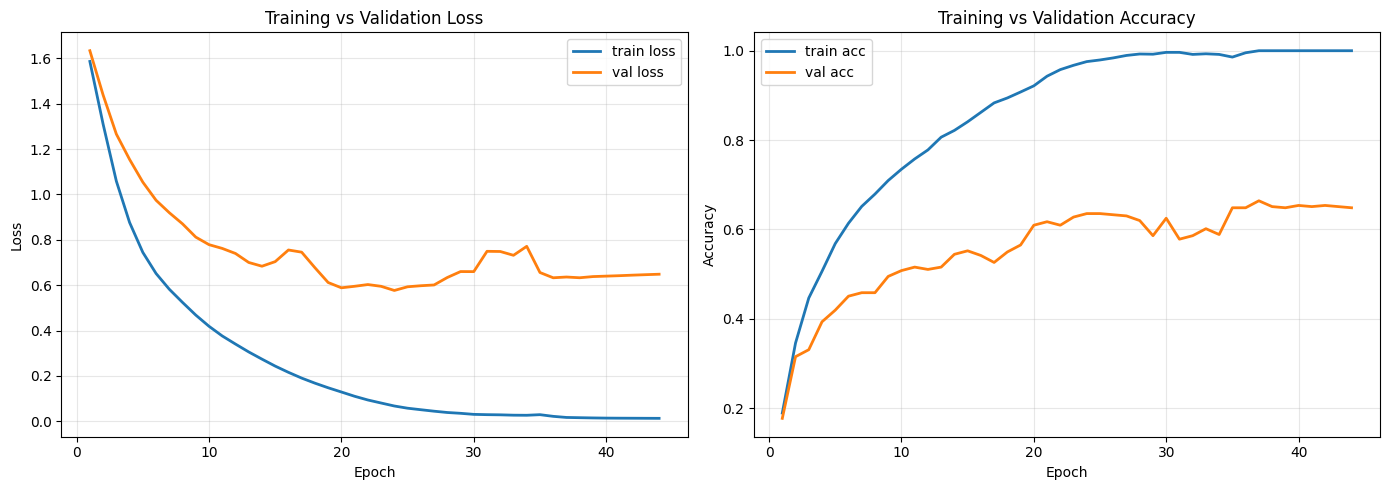

Saved curves to /kaggle/working/results_multibranch_pretraining_model1_large_bfrb_bayes/20261021_014301/validation_protocols/sequence/multibranch_pretraining_model1_large_curves.png
Epochs run: 44
Best val_loss epoch: 24  (val_loss=0.5767)


In [9]:
if experiment_succeeded:
    best_model = search.best_estimator_
    save_dir = last_run['results_dir']
    save_dir.mkdir(parents=True, exist_ok=True)

    # --- pull the history out of the fitted pipeline ---
    best_estimator = best_model.named_steps['estimator']
    history = best_estimator.get_history_dict()   # fine-tuning history
    pretraining_history = getattr(best_estimator, 'pretraining_history_', {})
    with open(save_dir / 'pretraining_history.json', 'w') as stream:
        json.dump(pretraining_history, stream, indent=2, default=str)
    print('Pretraining history:', pretraining_history)

    loss      = history.get('loss', [])
    val_loss  = history.get('val_loss', [])
    acc       = history.get('accuracy', history.get('predictions_accuracy', []))
    val_acc   = history.get('val_accuracy', history.get('val_predictions_accuracy', []))

    has_val = len(val_loss) > 0 and len(val_acc) > 0
    epochs_ran = range(1, len(loss) + 1)

    # --- two subplots, two lines each ---
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # ---- Loss ----
    ax = axes[0]
    ax.plot(epochs_ran, loss, label='train loss', linewidth=2)
    if has_val:
        ax.plot(epochs_ran, val_loss, label='val loss', linewidth=2)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss')
    ax.set_title('Training vs Validation Loss')
    ax.grid(alpha=0.3)
    ax.legend()

    # ---- Accuracy ----
    ax = axes[1]
    ax.plot(epochs_ran, acc, label='train acc', linewidth=2)
    if has_val:
        ax.plot(epochs_ran, val_acc, label='val acc', linewidth=2)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Accuracy')
    ax.set_title('Training vs Validation Accuracy')
    ax.grid(alpha=0.3)
    ax.legend()

    plt.tight_layout()

    # save next to the other results (save_dir is defined in your last cell)
    curves_path = save_dir / f'{experiment_name}_curves.png'
    # plt.savefig(curves_path, dpi=150, bbox_inches='tight')
    plt.show()

    print(f'Saved curves to {curves_path}')
    print(f'Epochs run: {len(loss)}')
    if has_val:
        best_epoch = int(np.argmin(val_loss)) + 1
        print(f'Best val_loss epoch: {best_epoch}  (val_loss={min(val_loss):.4f})')

In [10]:
# Each protocol's holdout was evaluated once after its own search/refit.
if experiment_succeeded:
    print('Last validation protocol:', last_run['validation_mode'])
    print('Holdout competition score:', eval_results['competition_score'])
pd.DataFrame(protocol_results)


Last validation protocol: sequence
Holdout competition score: 0.8138276233321904


,validation_mode,group_column,status,best_cv_score,holdout_score,results_dir
0,sequence,None,complete,0.771329,0.813828,/kaggle/working/results_multibranch_pretrainin...


In [11]:
# CV, best, holdout, histories and diagnostics are saved separately per protocol.
protocol_summary = pd.DataFrame(protocol_results)
print(protocol_summary.to_string(index=False))
print('Results:', validation_runs['results_dir'])


validation_mode group_column   status  best_cv_score  holdout_score                                                                                                           results_dir
       sequence         None complete       0.771329       0.813828 /kaggle/working/results_multibranch_pretraining_model1_large_bfrb_bayes/20261021_014301/validation_protocols/sequence
Results: /kaggle/working/results_multibranch_pretraining_model1_large_bfrb_bayes/20261021_014301/validation_protocols
